# 🚗 Used Car Price Segment Prediction (CarDekho Dataset)
### Data Science & Machine Learning Project (Python)

**Dataset:** Vehicle dataset from CarDekho (`Car details v3.csv`) – Kaggle
🔗 https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho

**Problem Statement:** Ek used car ki details (age, km chalna, engine, fuel, brand, etc.) dekh kar predict karna ki wo car **Low / Mid / High** price segment me aayegi.
Price ek continuous number hai, isliye hum `selling_price` ko 3 barabar classes me todenge (classification problem).

---
### Project Objectives (5)
| # | Objective |
|---|---|
| 1 | Car ke price ko kaun se factors sabse zyada affect karte hain? |
| 2 | Car age aur km_driven badhne par price kitna girta hai (depreciation)? |
| 3 | Fuel type aur transmission ka price par kya asar hai? |
| 4 | Owner count aur seller type se resale price me kitna fark aata hai? |
| 5 | KNN, Naive Bayes, Random Forest aur Logistic Regression me se **best model** kaun sa hai? |

### Notebook ka flow
1. Libraries & data load
2. Data cleaning (duplicates, inconsistent data, missing values, outliers)
3. Feature engineering (nayi columns)
4. Exploratory Data Analysis (EDA)
5. Objectives 1 to 4 (visualizations ke saath)
6. Encoding, train-test split aur scaling
7. Machine Learning models (4 classification models)
8. Model evaluation aur Objective 5
9. Findings, conclusion aur recommendations

## 1. Libraries import karna aur data load karna

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Libraries import ho gayi")

Libraries import ho gayi


In [2]:
# Kaggle se download ki hui file isi notebook wale folder me rakho.
# Kaggle/Colab me chala rahe ho to path badal lena, jaise:
# "/kaggle/input/vehicle-dataset-from-cardekho/Car details v3.csv"
df = pd.read_csv("Car details v3.csv")

print("Rows aur Columns:", df.shape)
df.head()

Rows aur Columns: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
# Data ki basic jaankari
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [4]:
# Numeric columns ka summary
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


## 2. Data Cleaning

Is section me hum 4 kaam karenge:
1. **Duplicate rows** hatana
2. **Inconsistent data** theek karna (text me chhupe numbers, alag-alag units, galat values)
3. **Missing values** bharna
4. **Outliers** ko sambhalna

### 2.1 Duplicate rows

In [5]:
print("Duplicate rows (pehle):", df.duplicated().sum())

df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Duplicate rows (baad me):", df.duplicated().sum())
print("Naya shape:", df.shape)

Duplicate rows (pehle): 1202
Duplicate rows (baad me): 0
Naya shape: (6926, 13)


### 2.2 Inconsistent data

Pehle dekhte hain kaun si columns me dikkat hai.

In [6]:
# Categorical columns ki unique values dekhte hain
print("Owner:\n", df["owner"].value_counts(), "\n")
print("Fuel:\n", df["fuel"].value_counts(), "\n")
print("Seller type:\n", df["seller_type"].value_counts(), "\n")
print("Transmission:\n", df["transmission"].value_counts())

Owner:
 owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64 

Fuel:
 fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64 

Seller type:
 seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64 

Transmission:
 transmission
Manual       6342
Automatic     584
Name: count, dtype: int64


In [7]:
# mileage, engine, max_power, torque columns text me hain (e.g. "23.4 kmpl", "1248 CC", "74 bhp")
print(df[["mileage", "engine", "max_power", "torque"]].head(8))

# mileage me do alag units hain
print("\nkmpl wale rows :", df["mileage"].astype(str).str.contains("kmpl").sum())
print("km/kg wale rows:", df["mileage"].astype(str).str.contains("km/kg").sum())

# torque me Nm aur kgm dono units hain
print("\ntorque me Nm wale rows :", df["torque"].astype(str).str.lower().str.contains("nm").sum())
print("torque me kgm wale rows:", df["torque"].astype(str).str.lower().str.contains("kgm").sum())

      mileage   engine   max_power                    torque
0   23.4 kmpl  1248 CC      74 bhp            190Nm@ 2000rpm
1  21.14 kmpl  1498 CC  103.52 bhp       250Nm@ 1500-2500rpm
2   17.7 kmpl  1497 CC      78 bhp     12.7@ 2,700(kgm@ rpm)
3   23.0 kmpl  1396 CC      90 bhp  22.4 kgm at 1750-2750rpm
4   16.1 kmpl  1298 CC    88.2 bhp     11.5@ 4,500(kgm@ rpm)
5  20.14 kmpl  1197 CC   81.86 bhp         113.75nm@ 4000rpm
6  17.3 km/kg  1061 CC    57.5 bhp      7.8@ 4,500(kgm@ rpm)
7   16.1 kmpl   796 CC      37 bhp             59Nm@ 2500rpm

kmpl wale rows : 6631
km/kg wale rows: 87

torque me Nm wale rows : 6227
torque me kgm wale rows: 481


**Problems jo mili:**
- `mileage`, `engine`, `max_power`, `torque` text me hain, number me nahi.
- `mileage` ka unit kisi me `kmpl` hai, kisi me `km/kg` (CNG/LPG cars).
- `torque` kisi me **Nm** me hai, kisi me **kgm** me. Dono ko ek unit (Nm) me lana hoga (1 kgm = 9.80665 Nm).
- `owner` me "Test Drive Car" wali rows hain, jo normal used cars nahi hain.
- `max_power` aur kuch columns me `0` jaisi galat value ho sakti hai.
- Kuch rows me torque "kgm" likha hai par number asal me Nm me hai (e.g. `145@ 4,100(kgm@ rpm)`). Aisi values ko hum convert nahi karenge.

In [8]:
# Function 1: text me se pehla number nikalna. Example: "23.4 kmpl" -> 23.4
def get_number(text):
    if pd.isnull(text):
        return np.nan
    text = str(text)
    number = ""
    for ch in text:
        if ch.isdigit() or ch == ".":
            number = number + ch
        else:
            if number != "":
                break
    if number == "" or number == ".":
        return np.nan
    try:
        return float(number)
    except:
        return np.nan


# Function 2: torque ko Nm me badalna
def get_torque_nm(text):
    value = get_number(text)
    if pd.isnull(value):
        return np.nan
    text = str(text).lower()
    if "nm" in text:
        return value                 # pehle se Nm me hai
    if "kgm" in text:
        if value > 50:
            return value             # kgm me 50 se zyada possible nahi, to ye asal me Nm hi hai (dataset ki galti)
        return value * 9.80665       # kgm ko Nm me convert
    return value                     # unit nahi likha hai, to Nm maan lete hain


# Test karke dekho
print(get_number("23.4 kmpl"))
print(get_number("1248 CC"))
print(get_torque_nm("190Nm@ 2000rpm"))
print(get_torque_nm("22.4 kgm at 1750-2750rpm"))

23.4
1248.0
190.0
219.66895999999997


In [9]:
# "Test Drive Car" wali rows hatao
print("Test Drive Car rows:", (df["owner"] == "Test Drive Car").sum())
df = df[df["owner"] != "Test Drive Car"]

# Text columns ko numbers me badlo
df["mileage"] = df["mileage"].apply(get_number)
df["engine"] = df["engine"].apply(get_number)
df["max_power"] = df["max_power"].apply(get_number)
df["torque_nm"] = df["torque"].apply(get_torque_nm)

# Purani text wali torque column hata do
df = df.drop(columns=["torque"])

# 0 value in columns me galat hai (engine ya power 0 nahi ho sakta), isko missing (NaN) maan lo
for col in ["mileage", "engine", "max_power"]:
    print(col, "me 0 values:", (df[col] == 0).sum())
    df.loc[df[col] == 0, col] = np.nan

df = df.reset_index(drop=True)
df[["mileage", "engine", "max_power", "torque_nm"]].describe()

Test Drive Car rows: 5
mileage me 0 values: 15
engine me 0 values: 0
max_power me 0 values: 3


,mileage,engine,max_power,torque_nm
count,6698.000000,6713.000000,6712.000000,6712.000000
mean,19.510809,1430.662446,87.710610,170.739205
std,3.947586,493.594859,31.658543,84.373904
min,9.000000,624.000000,32.800000,47.071920
25%,16.800000,1197.000000,67.100000,110.000000
50%,19.490000,1248.000000,81.830000,160.000000
75%,22.540000,1498.000000,100.000000,200.055660
max,42.000000,3604.000000,400.000000,789.000000


### 2.3 Missing values

mileage      223
engine       208
max_power    209
seats        208
torque_nm    209
dtype: int64


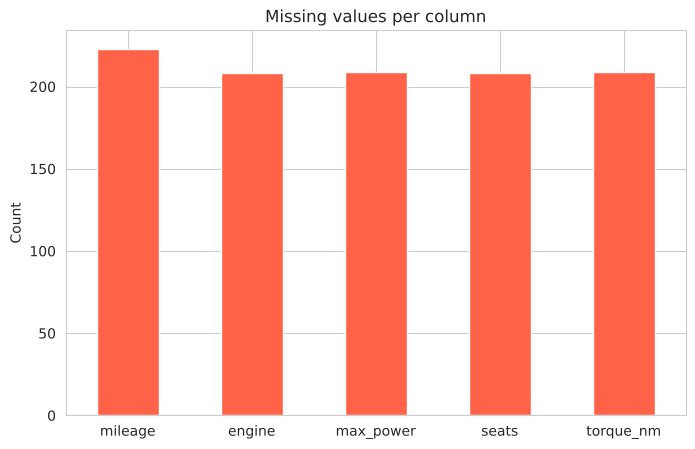

In [10]:
missing = df.isnull().sum()
print(missing[missing > 0])

# Missing values ka bar chart
missing[missing > 0].plot(kind="bar", color="tomato")
plt.title("Missing values per column")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [11]:
# Numeric columns -> median se bharo (outliers se kam asar padta hai)
for col in ["mileage", "engine", "max_power", "torque_nm"]:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# seats -> sabse zyada aane wali value (mode) se bharo
df["seats"] = df["seats"].fillna(df["seats"].mode()[0])
df["seats"] = df["seats"].astype(int)

print("Ab missing values:", df.isnull().sum().sum())

Ab missing values: 0


> **Note:** Yahan median poore data se nikala hai (simple rakhne ke liye). Strictly, median sirf train data se nikalna chahiye, par yahan sirf ~3% rows missing thi, isliye asar bahut chhota hai.

### 2.4 Outliers

`km_driven` aur `selling_price` me kuch bahut bade values ho sakte hain. Boxplot se dekhte hain.

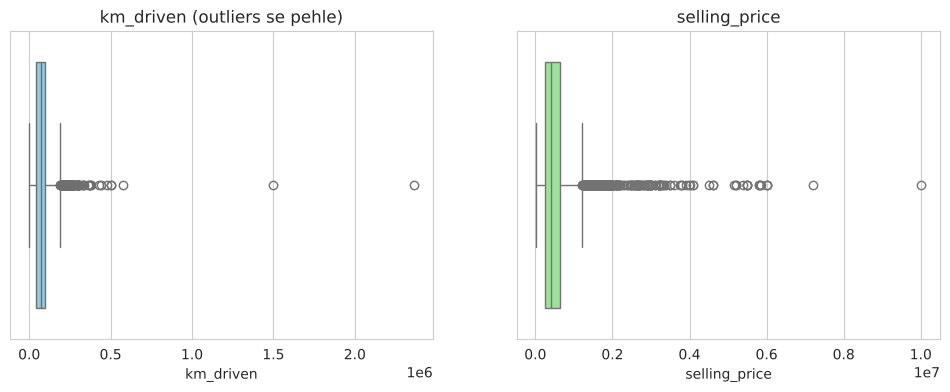

Sabse zyada km_driven: 2360457


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df["km_driven"], ax=axes[0], color="skyblue")
axes[0].set_title("km_driven (outliers se pehle)")

sns.boxplot(x=df["selling_price"], ax=axes[1], color="lightgreen")
axes[1].set_title("selling_price")

plt.show()
print("Sabse zyada km_driven:", df["km_driven"].max())

In [13]:
# km_driven ko 99th percentile par cap kar do (bahut extreme values ko control karne ke liye)
limit = df["km_driven"].quantile(0.99)
print("99th percentile limit:", limit)

df["km_driven"] = df["km_driven"].clip(upper=limit)
print("Cap ke baad max km_driven:", df["km_driven"].max())

# selling_price ko hum cap nahi kar rahe, kyunki aage hum use 3 equal classes me todenge
# (extreme price waali luxury cars bas "High" class me chali jayengi)

99th percentile limit: 239890.2000000001
Cap ke baad max km_driven: 239890.2000000001


## 3. Feature Engineering

Purane columns se nayi, zyada kaam ki columns banate hain:

| New column | Kaise bana | Kyun useful |
|---|---|---|
| `brand` | `name` ka pehla word | Brand price ko bahut affect karta hai |
| `car_age` | latest year − year | Year se zyada seedha "kitni purani" |
| `km_per_year` | km_driven / (car_age + 1) | Car kitni heavily use hui |
| `power_per_cc` | max_power / engine | Engine kitna efficient/powerful hai |
| `price_lakh` | selling_price / 1,00,000 | Charts padhne me aasan |
| `price_class` | selling_price ko 3 barabar parts me | **Target (Low / Mid / High)** |

In [14]:
# 1) Brand = name ka pehla word
df["brand"] = df["name"].str.split().str[0]
df.loc[df["brand"] == "Land", "brand"] = "Land Rover"      # "Land Rover" 2 words ka hai

# 2) Car age (dataset me sabse nayi car ka year = latest year)
latest_year = df["year"].max()
print("Latest year in data:", latest_year)
df["car_age"] = latest_year - df["year"]

# 3) Km per year
df["km_per_year"] = df["km_driven"] / (df["car_age"] + 1)

# 4) Power per cc
df["power_per_cc"] = df["max_power"] / df["engine"]

# 5) Price lakh me
df["price_lakh"] = df["selling_price"] / 100000

df[["name", "brand", "year", "car_age", "km_driven", "km_per_year", "power_per_cc"]].head()

Latest year in data: 2020


,name,brand,year,car_age,km_driven,km_per_year,power_per_cc
0,Maruti Swift Dzire VDI,Maruti,2014,6,145500.0,20785.714286,0.059295
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,6,120000.0,17142.857143,0.069105
2,Honda City 2017-2020 EXi,Honda,2006,14,140000.0,9333.333333,0.052104
3,Hyundai i20 Sportz Diesel,Hyundai,2010,10,127000.0,11545.454545,0.064470
4,Maruti Swift VXI BSIII,Maruti,2007,13,120000.0,8571.428571,0.067951


In [15]:
# 6) TARGET: price ko 3 barabar classes me todo (qcut = har class me lagbhag barabar cars)
df["price_class"] = pd.qcut(df["selling_price"], q=3, labels=["Low", "Mid", "High"])

# Har class ki price range dekhte hain
class_summary = df.groupby("price_class", observed=True)["price_lakh"].agg(["min", "max", "count"])
class_summary.columns = ["Min price (lakh)", "Max price (lakh)", "Cars"]
class_summary

,Min price (lakh),Max price (lakh),Cars
price_class,,,
Low,0.29999,3.0,2462
Mid,3.02000,5.5,2210
High,5.51000,100.0,2249


Matlab agar car ka price **Low** class ki upper limit se kam hai to wo budget car hai, **Mid** me beech wali, aur **High** me premium cars aati hain.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Target (price) ka distribution

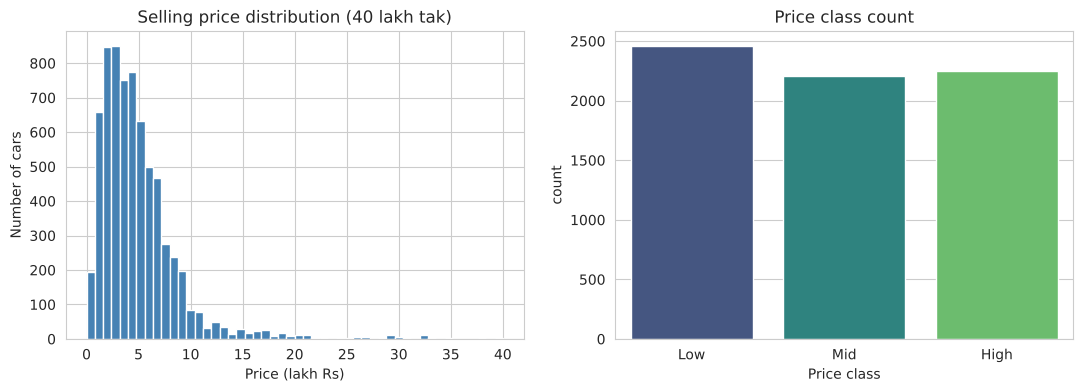

price_class
Low     2462
High    2249
Mid     2210
Name: count, dtype: int64


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Price histogram (40 lakh tak, taaki chart saaf dikhe)
axes[0].hist(df["price_lakh"], bins=50, range=(0, 40), color="steelblue", edgecolor="white")
axes[0].set_title("Selling price distribution (40 lakh tak)")
axes[0].set_xlabel("Price (lakh Rs)")
axes[0].set_ylabel("Number of cars")

# Class balance
sns.countplot(x="price_class", data=df, order=["Low", "Mid", "High"], ax=axes[1], palette="viridis")
axes[1].set_title("Price class count")
axes[1].set_xlabel("Price class")

plt.show()
print(df["price_class"].value_counts())

### 4.2 Categorical columns

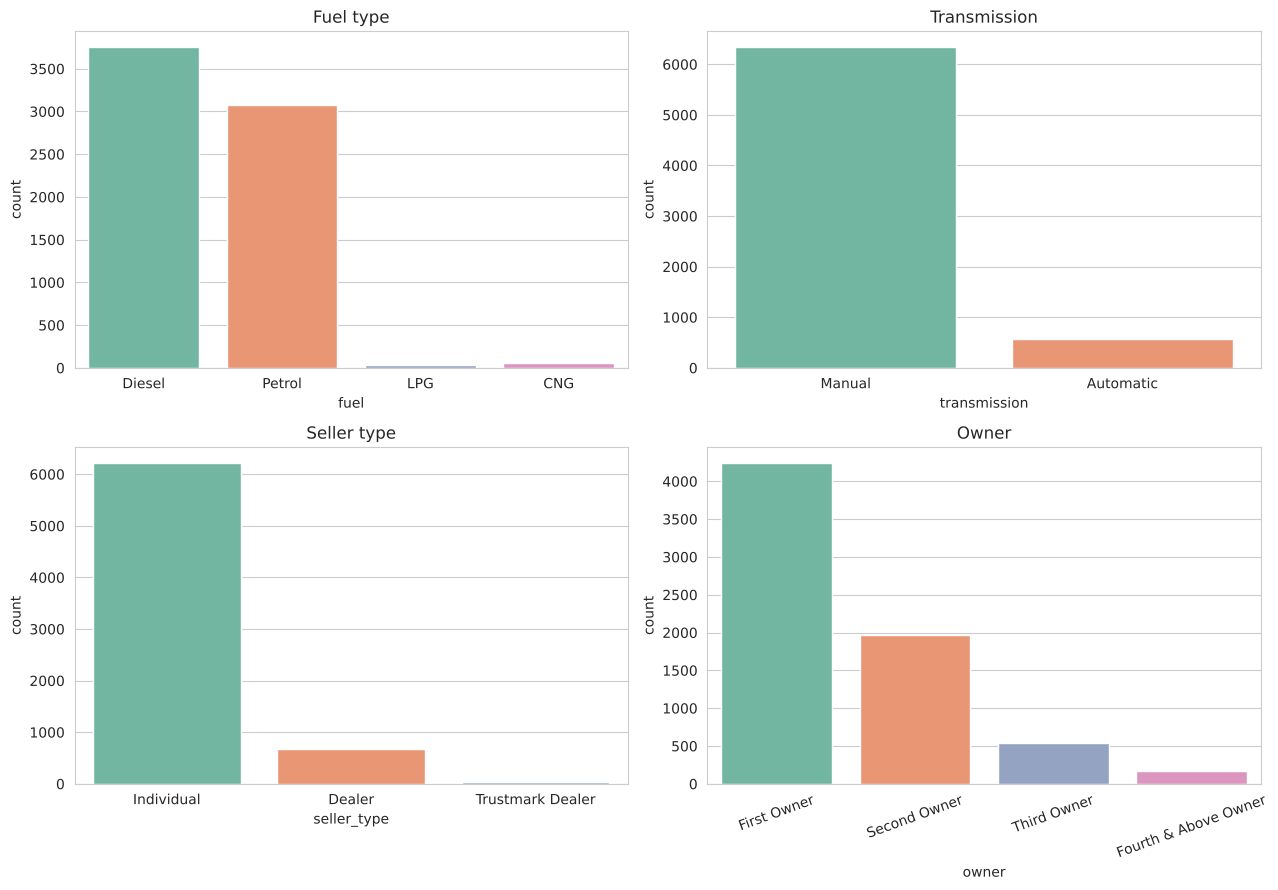

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(x="fuel", data=df, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Fuel type")

sns.countplot(x="transmission", data=df, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Transmission")

sns.countplot(x="seller_type", data=df, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Seller type")

sns.countplot(x="owner", data=df, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("Owner")
axes[1, 1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 4.3 Numeric columns ka distribution

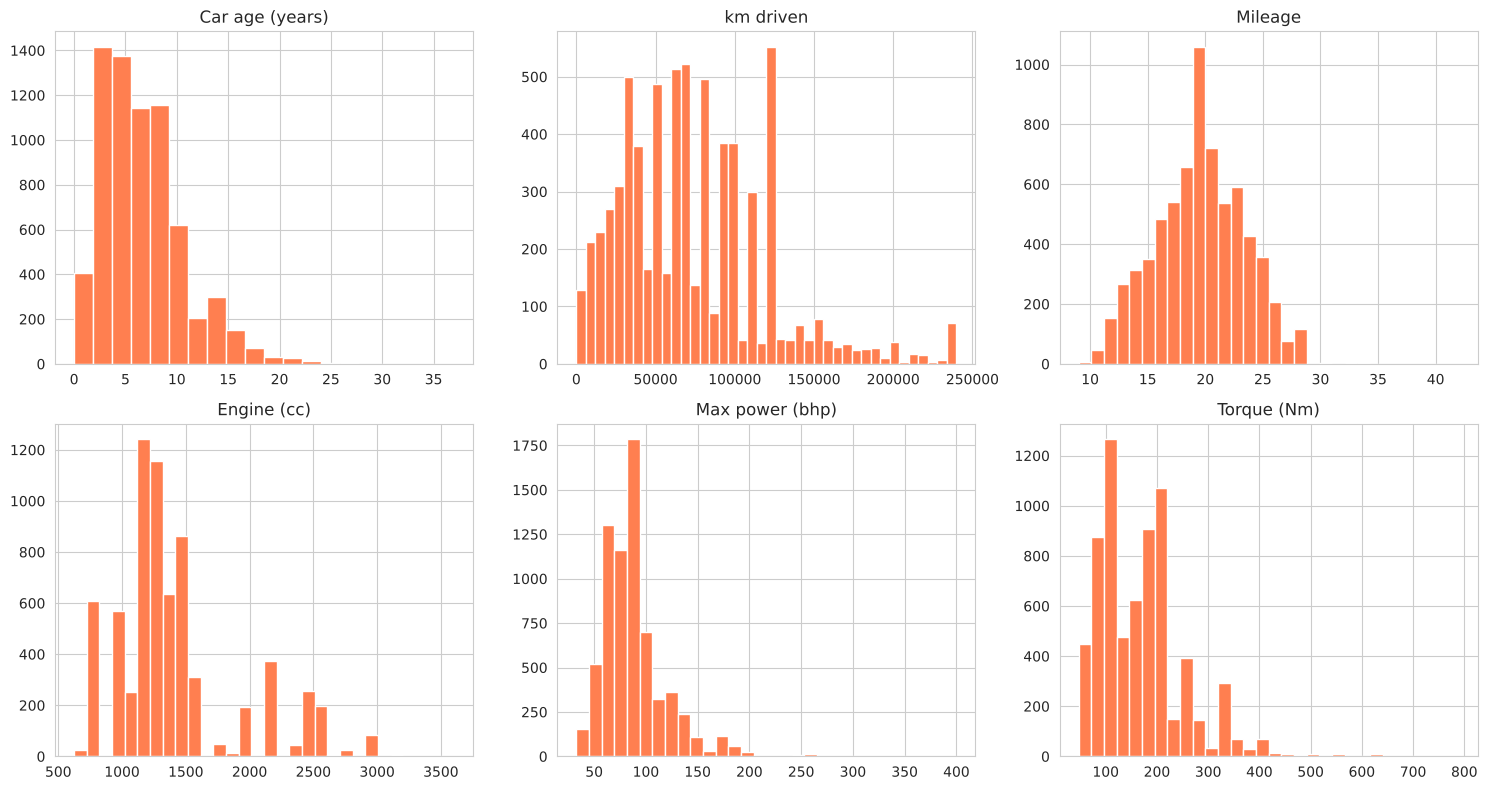

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].hist(df["car_age"], bins=20, color="coral", edgecolor="white")
axes[0, 0].set_title("Car age (years)")

axes[0, 1].hist(df["km_driven"], bins=40, color="coral", edgecolor="white")
axes[0, 1].set_title("km driven")

axes[0, 2].hist(df["mileage"], bins=30, color="coral", edgecolor="white")
axes[0, 2].set_title("Mileage")

axes[1, 0].hist(df["engine"], bins=30, color="coral", edgecolor="white")
axes[1, 0].set_title("Engine (cc)")

axes[1, 1].hist(df["max_power"], bins=30, color="coral", edgecolor="white")
axes[1, 1].set_title("Max power (bhp)")

axes[1, 2].hist(df["torque_nm"], bins=30, color="coral", edgecolor="white")
axes[1, 2].set_title("Torque (Nm)")

plt.tight_layout()
plt.show()

### 4.4 Top 10 brands

brand
Maruti        2165
Hyundai       1267
Mahindra       723
Tata           647
Honda          361
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     173
Name: count, dtype: int64


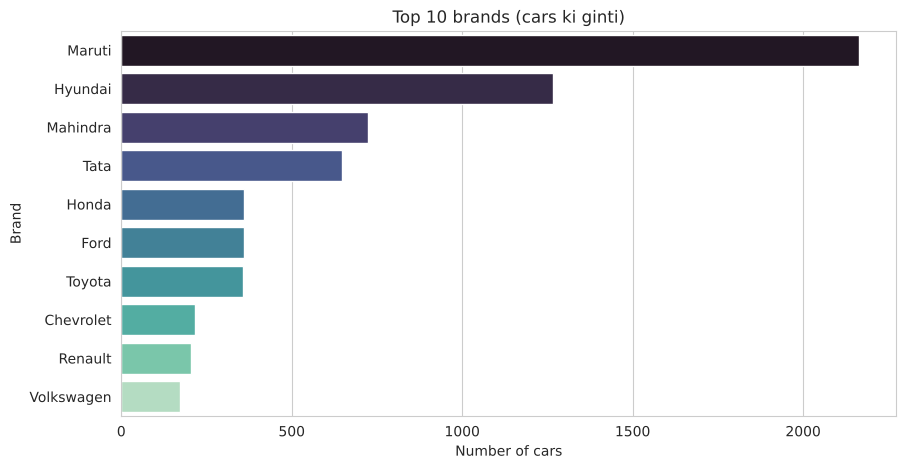

In [19]:
top10 = df["brand"].value_counts().head(10)
print(top10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top10.values, y=top10.index, palette="mako")
plt.title("Top 10 brands (cars ki ginti)")
plt.xlabel("Number of cars")
plt.ylabel("Brand")
plt.show()

**EDA se pata chala:**
- Price right-skewed hai: median price lagbhag **4 lakh** hai, par kuch luxury cars 1 crore tak jaati hain.
- Teeno classes lagbhag barabar hain: **Low** (3 lakh tak), **Mid** (3 se 5.5 lakh), **High** (5.5 lakh se upar). Isliye class imbalance ki dikkat nahi.
- Zyadatar cars **Diesel (3755)** ya **Petrol (3077)** hain, **Manual (6342)** hain aur **First Owner (4242)** ki hain.
- Lagbhag 90% cars **Individual** sellers ki hain (6218 me se).
- Top brands: **Maruti (2165)** aur **Hyundai (1267)** sabse aage hain.

## 5. Objectives ka Analysis (Visualizations ke saath)

### 🎯 Objective 1: Price ko kaun se factors sabse zyada affect karte hain?
Correlation numbers batata hai ki do columns saath me kitna badhte/ghat-te hain (+1 = saath badhte, −1 = ek badhe to doosra ghate, 0 = koi rishta nahi).

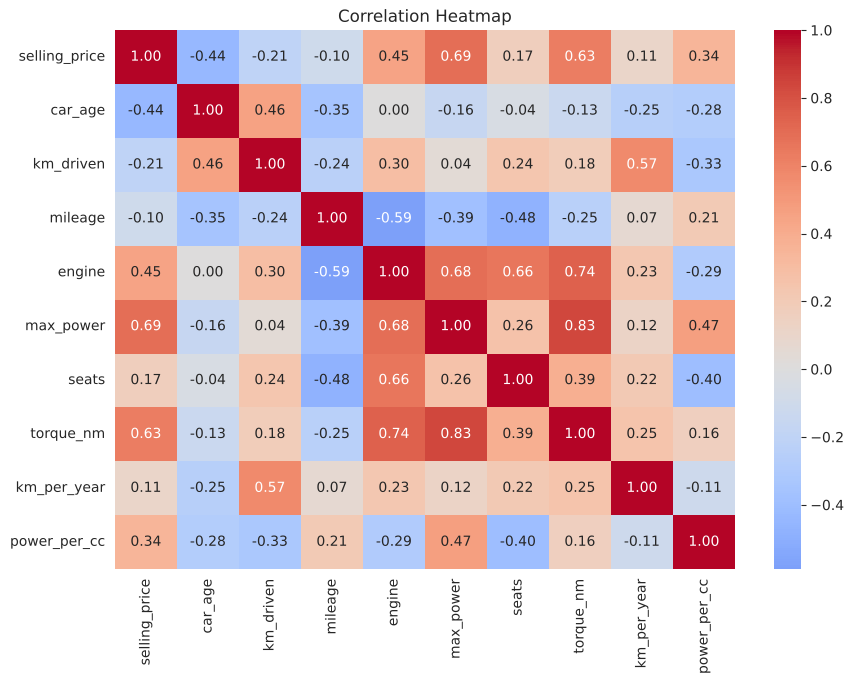

In [20]:
num_cols = ["selling_price", "car_age", "km_driven", "mileage", "engine",
            "max_power", "seats", "torque_nm", "km_per_year", "power_per_cc"]

corr = df[num_cols].corr()

# Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

car_age        -0.44
km_driven      -0.21
mileage        -0.10
km_per_year     0.11
seats           0.17
power_per_cc    0.34
engine          0.45
torque_nm       0.63
max_power       0.69
Name: selling_price, dtype: float64


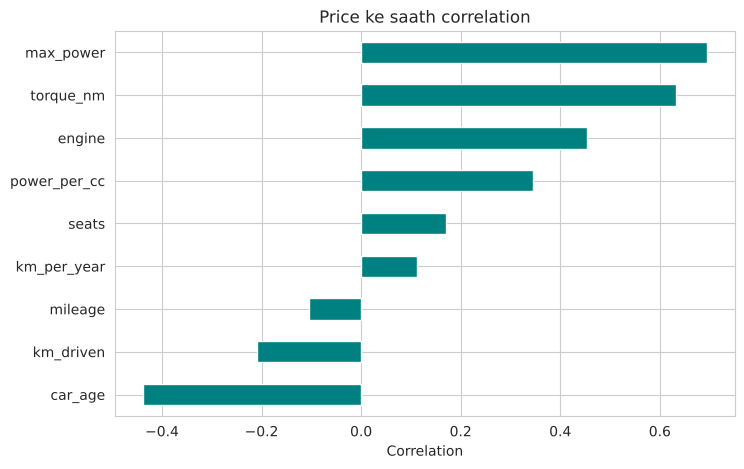

In [21]:
# Sirf selling_price ke saath correlation
corr_price = corr["selling_price"].drop("selling_price").sort_values()
print(corr_price.round(2))

plt.figure(figsize=(8, 5))
corr_price.plot(kind="barh", color="teal")
plt.title("Price ke saath correlation")
plt.xlabel("Correlation")
plt.show()

**Observation (Objective 1):**
- **max_power (0.69)** aur **torque_nm (0.63)** ka price ke saath sabse strong positive rishta hai. Engine (0.45) aur power_per_cc (0.34) bhi positive hain. Yaani zyada powerful car, zyada price.
- **car_age (−0.44)** negative hai: car jitni purani, price utna kam. **km_driven (−0.21)** ka asar kam par negative hai.
- Mileage ka price se negative rishta (−0.10) hai, kyunki badi powerful cars kam mileage deti hain.
- Dhyan rakho: max_power, torque aur engine aapas me bhi correlated hain, isliye teeno ka asar thoda overlap karta hai. Correlation ka matlab causation nahi hota.

### 🎯 Objective 2: Car age aur km_driven badhne par price kitna girta hai?

car_age
0     6.00
1     6.90
2     7.00
3     6.25
4     5.50
5     5.25
6     4.50
7     3.87
8     3.10
9     2.65
10    2.20
11    1.80
Name: price_lakh, dtype: float64


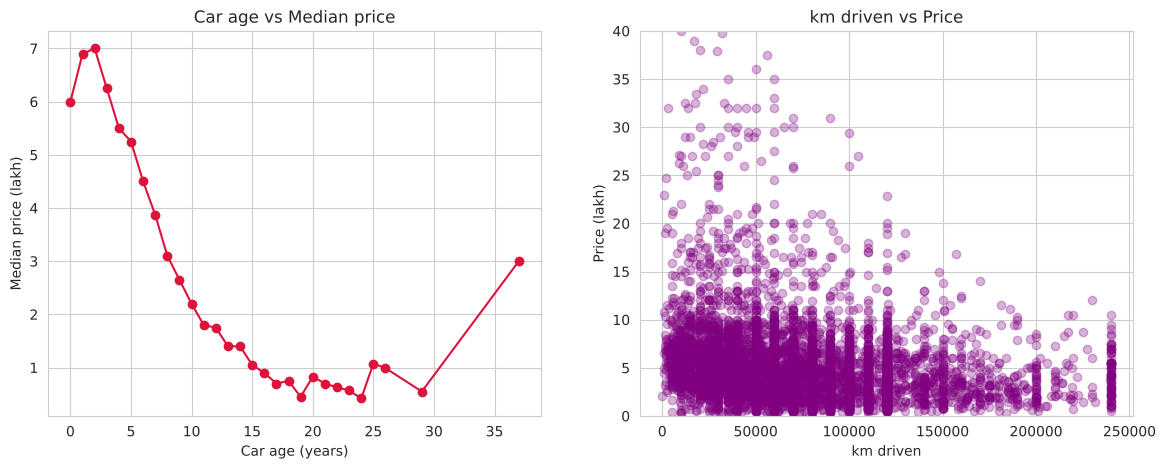

In [22]:
# Har age par median price
age_price = df.groupby("car_age")["price_lakh"].median()
print(age_price.round(2).head(12))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(age_price.index, age_price.values, marker="o", color="crimson")
axes[0].set_title("Car age vs Median price")
axes[0].set_xlabel("Car age (years)")
axes[0].set_ylabel("Median price (lakh)")

axes[1].scatter(df["km_driven"], df["price_lakh"], alpha=0.3, color="purple")
axes[1].set_ylim(0, 40)
axes[1].set_title("km driven vs Price")
axes[1].set_xlabel("km driven")
axes[1].set_ylabel("Price (lakh)")

plt.show()

age_group
0-3 yrs     6.55
4-6 yrs     5.00
7-10 yrs    3.00
10+ yrs     1.40
Name: price_lakh, dtype: float64


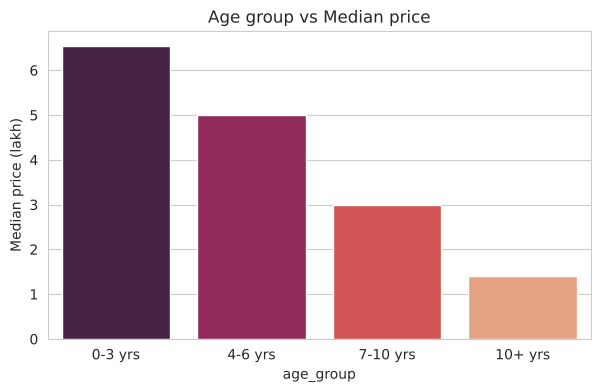

In [23]:
# Age ko groups me baant kar median price dekhte hain
def age_group(age):
    if age <= 3:
        return "0-3 yrs"
    elif age <= 6:
        return "4-6 yrs"
    elif age <= 10:
        return "7-10 yrs"
    else:
        return "10+ yrs"

df["age_group"] = df["car_age"].apply(age_group)

group_price = df.groupby("age_group")["price_lakh"].median()
group_price = group_price[["0-3 yrs", "4-6 yrs", "7-10 yrs", "10+ yrs"]]
print(group_price.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=group_price.index, y=group_price.values, palette="rocket")
plt.title("Age group vs Median price")
plt.ylabel("Median price (lakh)")
plt.show()

**Observation (Objective 2):**
- Median price age ke saath tezi se girta hai: **0-3 saal: 6.55 lakh**, **4-6 saal: 5.0 lakh**, **7-10 saal: 3.0 lakh**, **10+ saal: 1.4 lakh**. Yaani 10+ saal purani car 0-3 saal wali se lagbhag **79% sasti** hai.
- Age 0 se 2 tak median thoda badhta dikhta hai (6.0 se 7.0 lakh). Iska karan ye hai ki nayi cars me mix badal jata hai (zyada premium cars), na ki car ki value badhti hai.
- km_driven vs price scatter me dikhta hai ki zyada km chali cars ka price zyadatar kam range me hai, par fark age jitna sharp nahi hai.

### 🎯 Objective 3: Fuel type aur transmission ka price par kya asar hai?

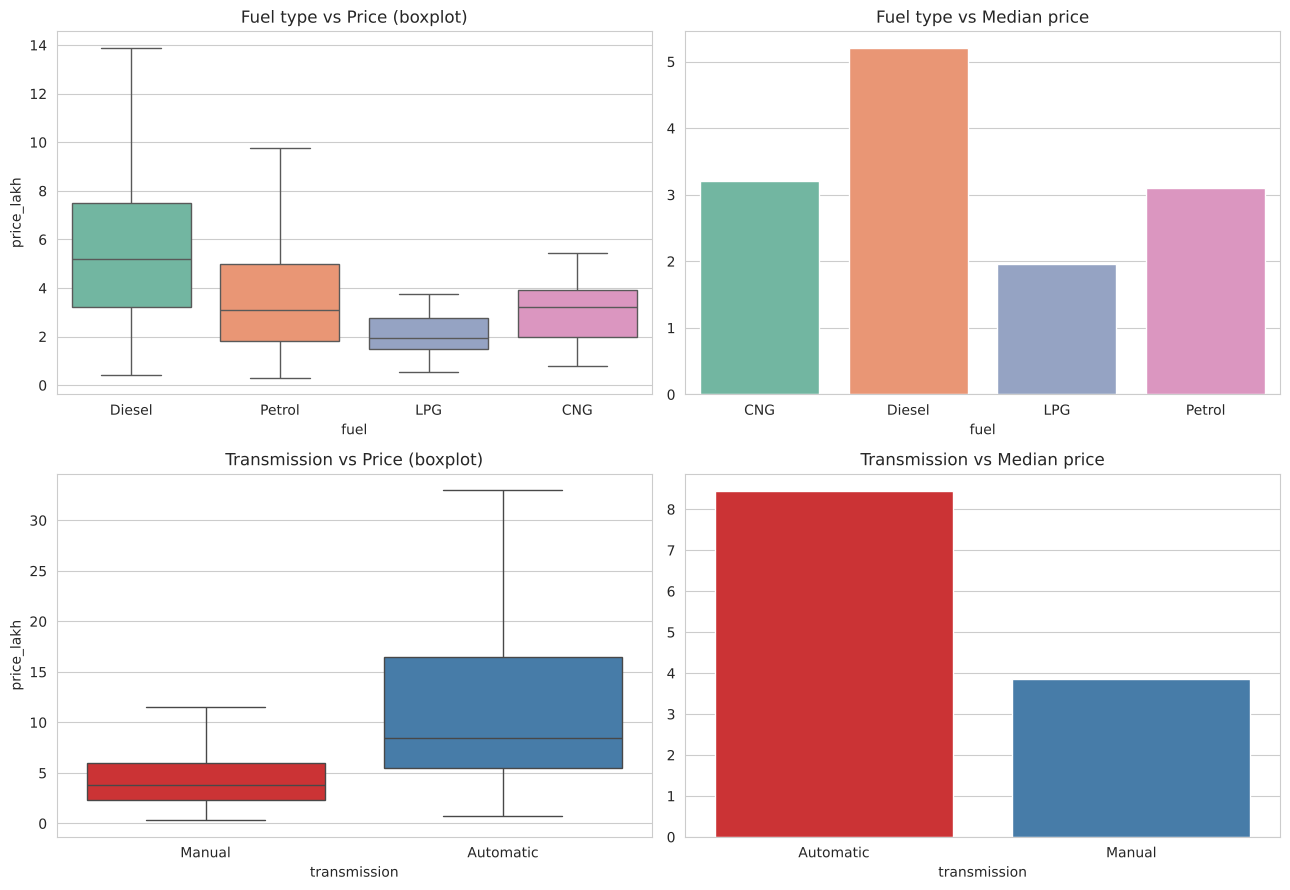

Fuel wise median price (lakh):
 fuel
CNG       3.20
Diesel    5.20
LPG       1.96
Petrol    3.10
Name: price_lakh, dtype: float64 

Transmission wise median price (lakh):
 transmission
Automatic    8.45
Manual       3.85
Name: price_lakh, dtype: float64


In [24]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Fuel: boxplot aur median bar
sns.boxplot(x="fuel", y="price_lakh", data=df, showfliers=False, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Fuel type vs Price (boxplot)")

fuel_median = df.groupby("fuel")["price_lakh"].median()
sns.barplot(x=fuel_median.index, y=fuel_median.values, ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Fuel type vs Median price")

# Transmission: boxplot aur median bar
sns.boxplot(x="transmission", y="price_lakh", data=df, showfliers=False, ax=axes[1, 0], palette="Set1")
axes[1, 0].set_title("Transmission vs Price (boxplot)")

trans_median = df.groupby("transmission")["price_lakh"].median()
sns.barplot(x=trans_median.index, y=trans_median.values, ax=axes[1, 1], palette="Set1")
axes[1, 1].set_title("Transmission vs Median price")

plt.tight_layout()
plt.show()

print("Fuel wise median price (lakh):\n", fuel_median.round(2), "\n")
print("Transmission wise median price (lakh):\n", trans_median.round(2))

fuel
CNG       23.67
Diesel    19.76
LPG       18.65
Petrol    19.14
Name: mileage, dtype: float64


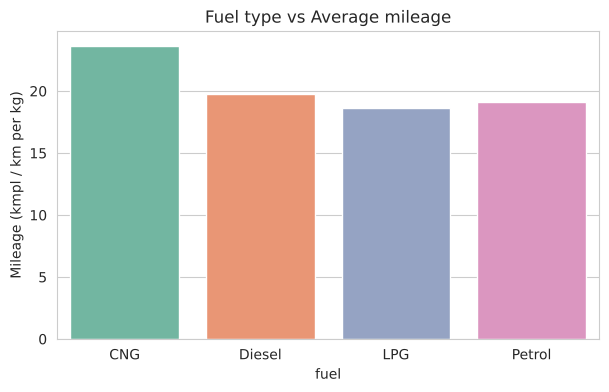

In [25]:
# Mileage par fuel ka asar
fuel_mileage = df.groupby("fuel")["mileage"].mean()
print(fuel_mileage.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=fuel_mileage.index, y=fuel_mileage.values, palette="Set2")
plt.title("Fuel type vs Average mileage")
plt.ylabel("Mileage (kmpl / km per kg)")
plt.show()

**Observation (Objective 3):**
- **Diesel** cars ka median price **5.2 lakh** hai, jabki **Petrol** ka **3.1 lakh** aur **CNG** ka **3.2 lakh**. (LPG me sirf 38 cars hain, isliye uske number par zyada bharosa mat karo.)
- **Automatic** cars ka median price **8.45 lakh** hai, **Manual** ka **3.85 lakh**, yaani automatic lagbhag **2.2 guna** mehngi.
- Mileage me **CNG** sabse upar hai (**23.7**, par unit km/kg hai), Diesel **19.8** aur Petrol **19.1** kmpl.
- Dhyan rakho: diesel aur automatic cars aksar badi, premium aur nayi bhi hoti hain. Isliye price ka fark sirf fuel ya transmission ki wajah se nahi, in sab factors ke mix se hai.

### 🎯 Objective 4: Owner count aur seller type se resale price me kitna fark aata hai?

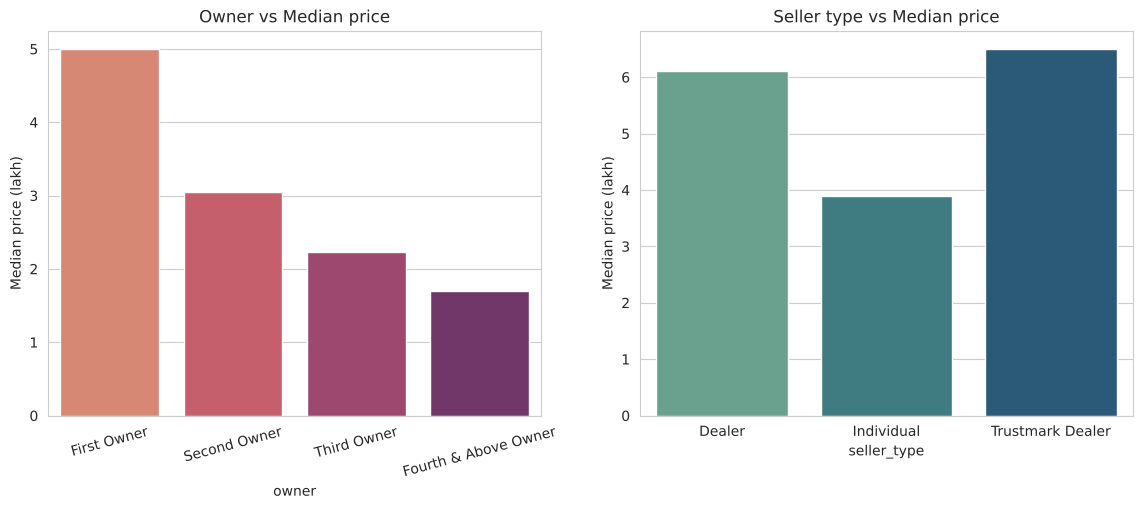

Owner wise median price (lakh):
 owner
First Owner             5.00
Second Owner            3.05
Third Owner             2.22
Fourth & Above Owner    1.70
Name: price_lakh, dtype: float64 

Seller wise median price (lakh):
 seller_type
Dealer              6.1
Individual          3.9
Trustmark Dealer    6.5
Name: price_lakh, dtype: float64


In [26]:
owner_order = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

owner_median = df.groupby("owner")["price_lakh"].median()
owner_median = owner_median[owner_order]
sns.barplot(x=owner_median.index, y=owner_median.values, ax=axes[0], palette="flare")
axes[0].set_title("Owner vs Median price")
axes[0].set_ylabel("Median price (lakh)")
axes[0].tick_params(axis="x", rotation=15)

seller_median = df.groupby("seller_type")["price_lakh"].median()
sns.barplot(x=seller_median.index, y=seller_median.values, ax=axes[1], palette="crest")
axes[1].set_title("Seller type vs Median price")
axes[1].set_ylabel("Median price (lakh)")

plt.show()

print("Owner wise median price (lakh):\n", owner_median.round(2), "\n")
print("Seller wise median price (lakh):\n", seller_median.round(2))

price_class        Low   Mid  High
seller_type                       
Dealer            12.6  30.0  57.4
Individual        38.2  32.2  29.6
Trustmark Dealer   3.7  25.9  70.4


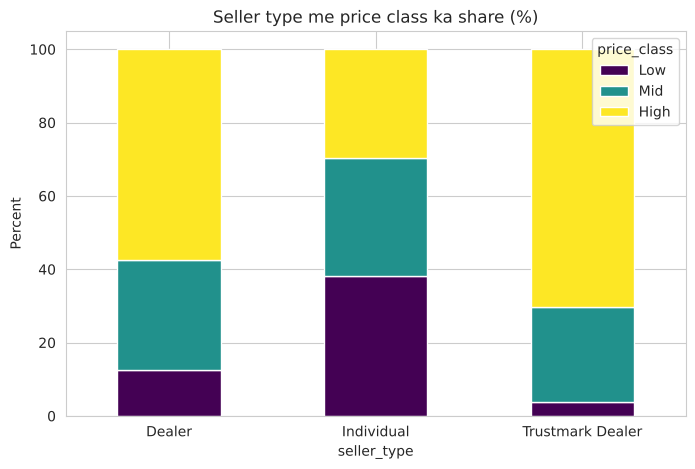

In [27]:
# Seller type ke andar price class ka share (%)
share = pd.crosstab(df["seller_type"], df["price_class"], normalize="index") * 100
print(share.round(1))

share.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Seller type me price class ka share (%)")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

**Observation (Objective 4):**
- Owner badalne par price girta hai: **First Owner: 5.0 lakh**, **Second: 3.05 lakh**, **Third: 2.22 lakh**, **Fourth & Above: 1.7 lakh**.
- **Dealer (6.1 lakh)** aur **Trustmark Dealer (6.5 lakh)** ki cars ka median price **Individual (3.9 lakh)** se zyada hai.
- **High** class ka share: Dealer me **57.4%**, Trustmark Dealer me **70.4%**, Individual me sirf **29.6%**.
- Dhyan rakho: Trustmark Dealer ke dataset me sirf 27 cars hain, isliye us number par zyada bharosa nahi karna chahiye. Dealers aksar nayi aur achhi condition ki cars bechte hain, isliye fark sirf seller type ki wajah se nahi hai.

### 🎯 Objective 5
Objective 5 (best ML model) ka jawab **Section 8** me milega, jahan 4 models compare karenge.

## 6. Model ke liye data taiyar karna

Machine learning models sirf **numbers** samajhte hain, isliye:
1. Text columns ko numbers me badlenge (**encoding**)
2. Data ko **train** aur **test** me baatenge
3. Numeric features ko **scale** karenge (taaki sab ek jaise range me ho)

### 6.1 Encoding

In [28]:
# 1) Owner: order hai (1st, 2nd, 3rd...), isliye 1,2,3,4 number de do
owner_map = {"First Owner": 1, "Second Owner": 2, "Third Owner": 3, "Fourth & Above Owner": 4}
df["owner_num"] = df["owner"].map(owner_map)

# 2) Transmission: sirf 2 values hain -> 0 aur 1
df["transmission_num"] = df["transmission"].map({"Manual": 0, "Automatic": 1})

# 3) Brand: bahut saare brands hain, isliye top 10 rakho aur baaki ko "Other" bana do
top_brands = df["brand"].value_counts().head(10).index.tolist()

def group_brand(b):
    if b in top_brands:
        return b
    return "Other"

df["brand_group"] = df["brand"].apply(group_brand)

# 4) Fuel, seller_type, brand_group: one-hot encoding (har category ki alag 0/1 column)
dummies = pd.get_dummies(df[["fuel", "seller_type", "brand_group"]], drop_first=True)
dummies = dummies.astype(int)

print("One-hot columns:", dummies.shape[1])
dummies.head()

One-hot columns: 15


,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,brand_group_Ford,brand_group_Honda,brand_group_Hyundai,brand_group_Mahindra,brand_group_Maruti,brand_group_Other,brand_group_Renault,brand_group_Tata,brand_group_Toyota,brand_group_Volkswagen
0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0
1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
2,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0
3,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0
4,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0


In [29]:
# Final features (X) aur target (y)
number_features = ["car_age", "km_driven", "mileage", "engine", "max_power",
                   "seats", "torque_nm", "km_per_year", "power_per_cc",
                   "owner_num", "transmission_num"]

X = pd.concat([df[number_features], dummies], axis=1)

# Target: Low=0, Mid=1, High=2
y = df["price_class"].map({"Low": 0, "Mid": 1, "High": 2})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", list(X.columns))

X shape: (6921, 26)
y shape: (6921,)
Features: ['car_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'km_per_year', 'power_per_cc', 'owner_num', 'transmission_num', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'brand_group_Ford', 'brand_group_Honda', 'brand_group_Hyundai', 'brand_group_Mahindra', 'brand_group_Maruti', 'brand_group_Other', 'brand_group_Renault', 'brand_group_Tata', 'brand_group_Toyota', 'brand_group_Volkswagen']


> ⚠️ **Important:** `selling_price` aur `price_lakh` ko features me **nahi** rakha, kyunki target isi se bana hai. Rakhte to model "cheat" kar leta (data leakage). `year` bhi nahi rakha kyunki `car_age` wahi information deta hai.

### 6.2 Train-Test split
80% data train ke liye, 20% test ke liye. `stratify=y` se teeno classes ka ratio dono me same rehta hai.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)
print("\nTrain class ratio:\n", y_train.value_counts(normalize=True).round(3))

Train size: (5536, 26)
Test size : (1385, 26)

Train class ratio:
 price_class
0    0.356
2    0.325
1    0.319
Name: proportion, dtype: float64


### 6.3 Scaling (StandardScaler)

`km_driven` lakho me hota hai, `seats` 2 se 10 me. KNN aur Logistic Regression jaise models bade numbers ko zyada importance de dete hain. **StandardScaler** har column ko mean = 0 aur std = 1 par le aata hai.

Scaler sirf **train data** par `fit` hota hai, phir train aur test dono par `transform`. Isse test data ki information model tak leak nahi hoti.

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)     # train par seekho + badlo
X_test_scaled = scaler.transform(X_test)           # test par sirf badlo

# Pehle aur baad ka comparison (3 columns)
before = X_train[["km_driven", "engine", "max_power"]].describe().loc[["mean", "std"]]
after = pd.DataFrame(X_train_scaled, columns=X.columns)[["km_driven", "engine", "max_power"]].describe().loc[["mean", "std"]]

print("Scaling se PEHLE:\n", before.round(2), "\n")
print("Scaling ke BAAD:\n", after.round(2))

Scaling se PEHLE:
       km_driven   engine  max_power
mean   72758.05  1425.65      87.71
std    45854.44   485.63      31.16 

Scaling ke BAAD:
       km_driven  engine  max_power
mean        0.0     0.0        0.0
std         1.0     1.0        1.0


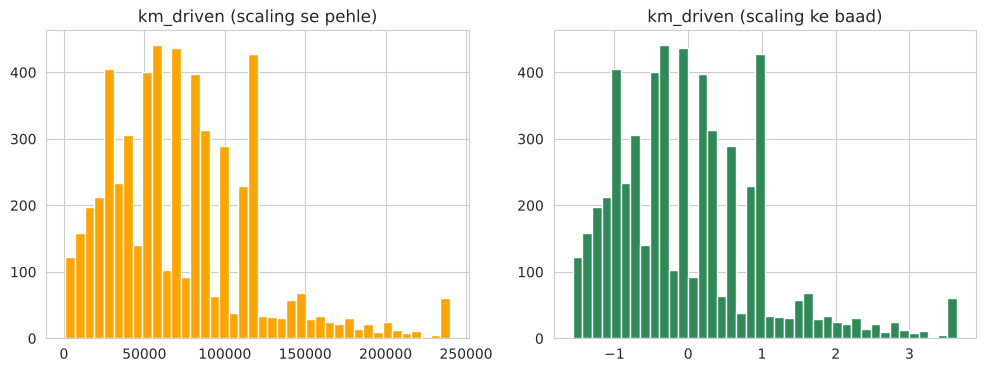

In [32]:
# Scaling ka visual effect (km_driven)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(X_train["km_driven"], bins=40, color="orange", edgecolor="white")
axes[0].set_title("km_driven (scaling se pehle)")

km_index = list(X.columns).index("km_driven")
axes[1].hist(X_train_scaled[:, km_index], bins=40, color="seagreen", edgecolor="white")
axes[1].set_title("km_driven (scaling ke baad)")

plt.show()

## 7. Machine Learning Models (Classification)

Hum 4 models train karenge:

| Model | Simple idea |
|---|---|
| **Logistic Regression** | Features ka weighted sum nikal kar har class ki probability batata hai |
| **KNN** | Naye car ke sabse paas ke K cars dekh kar unki majority class de deta hai |
| **Naive Bayes** | Bayes theorem + maanta hai ki saare features ek doosre se independent hain |
| **Random Forest** | Bahut saare decision trees ka group, sab vote karte hain |

### 7.1 KNN ke liye best K dhoondhna
K ki alag-alag values try karte hain aur **cross-validation** (train data ko 5 hisso me baant kar) se sabse achha K chunte hain. Test data yahan use nahi hota.

K = 1  CV accuracy = 0.7729
K = 3  CV accuracy = 0.7827
K = 5  CV accuracy = 0.7845


K = 7  CV accuracy = 0.7859
K = 9  CV accuracy = 0.7805


K = 11  CV accuracy = 0.7784
K = 15  CV accuracy = 0.7771


K = 21  CV accuracy = 0.769
K = 31  CV accuracy = 0.7558

Best K: 7


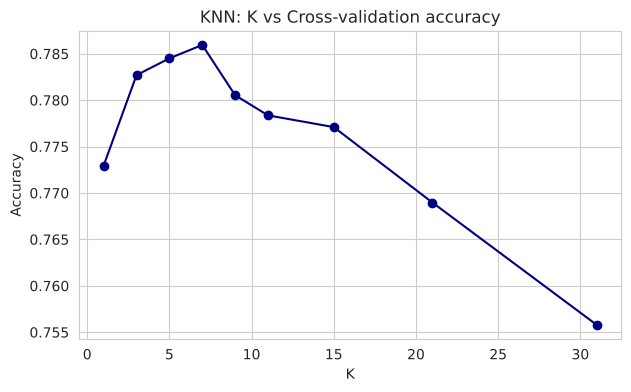

In [33]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring="accuracy").mean()
    k_scores.append(score)
    print("K =", k, " CV accuracy =", round(score, 4))

best_k = k_values[k_scores.index(max(k_scores))]
print("\nBest K:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, k_scores, marker="o", color="navy")
plt.title("KNN: K vs Cross-validation accuracy")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.show()

### 7.2 Models train karna

Ek simple function banate hain jo kisi bhi model ko train kare aur uske scores save kare.

In [34]:
results = []          # saare models ke scores yahan jama honge
predictions = {}      # saare models ki test predictions

def evaluate_model(name, model):
    # 1) Train
    model.fit(X_train_scaled, y_train)

    # 2) Predict
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    # 3) Scores nikalo
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred, average="macro")
    recall = recall_score(y_test, test_pred, average="macro")
    f1 = f1_score(y_test, test_pred, average="macro")
    cv_acc = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy").mean()

    # 4) Save karo
    results.append({
        "Model": name,
        "Train Accuracy": round(train_acc, 4),
        "CV Accuracy": round(cv_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-score": round(f1, 4)
    })
    predictions[name] = test_pred

    print(name, "-> Train:", round(train_acc, 3), "| Test:", round(test_acc, 3), "| F1:", round(f1, 3))

In [35]:
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
evaluate_model("Logistic Regression", log_model)

# Model 2: KNN (best K ke saath)
knn_model = KNeighborsClassifier(n_neighbors=best_k)
evaluate_model("KNN", knn_model)

# Model 3: Naive Bayes
nb_model = GaussianNB()
evaluate_model("Naive Bayes", nb_model)

# Model 4: Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
evaluate_model("Random Forest", rf_model)

Logistic Regression -> Train: 0.811 | Test: 0.819 | F1: 0.818


KNN -> Train: 0.843 | Test: 0.787 | F1: 0.786
Naive Bayes -> Train: 0.578 | Test: 0.578 | F1: 0.507


Random Forest -> Train: 0.99 | Test: 0.834 | F1: 0.832


## 8. Model Evaluation aur Objective 5 (Best Model)

**Metrics ka matlab:**
- **Accuracy:** kitne % predictions sahi the
- **Precision:** jab model ne "High" bola, to kitni baar wo sach me High thi
- **Recall:** jitni cars sach me High thi, unme se kitni model ne pakdi
- **F1-score:** Precision aur Recall ka balance (yahan *macro* average = teeno classes ko barabar importance)

In [36]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df

,Model,Train Accuracy,CV Accuracy,Test Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9897,0.8347,0.8339,0.8325,0.8321,0.8323
1,Logistic Regression,0.8109,0.8087,0.8195,0.8180,0.8175,0.8177
2,KNN,0.8427,0.7859,0.7870,0.7865,0.7853,0.7856
3,Naive Bayes,0.5777,0.5499,0.5783,0.5996,0.5722,0.5066


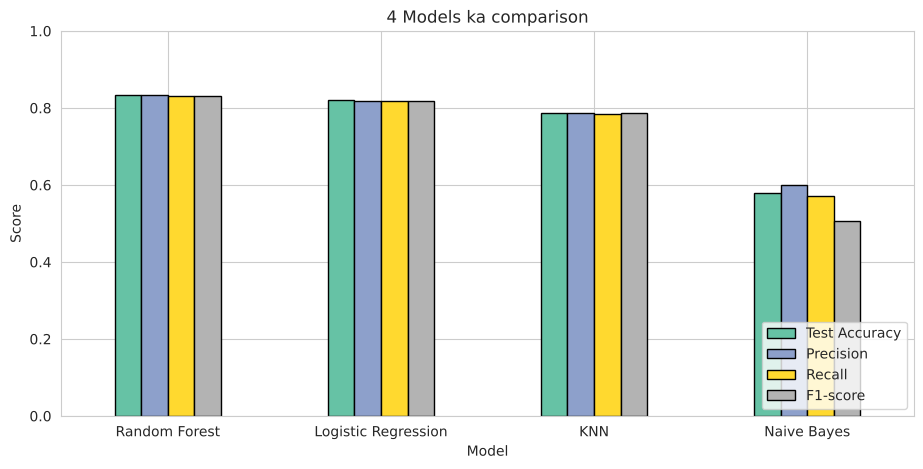

In [37]:
# Models ka comparison chart
metrics = ["Test Accuracy", "Precision", "Recall", "F1-score"]
plot_df = results_df.set_index("Model")[metrics]

plot_df.plot(kind="bar", figsize=(11, 5), colormap="Set2", edgecolor="black")
plt.title("4 Models ka comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

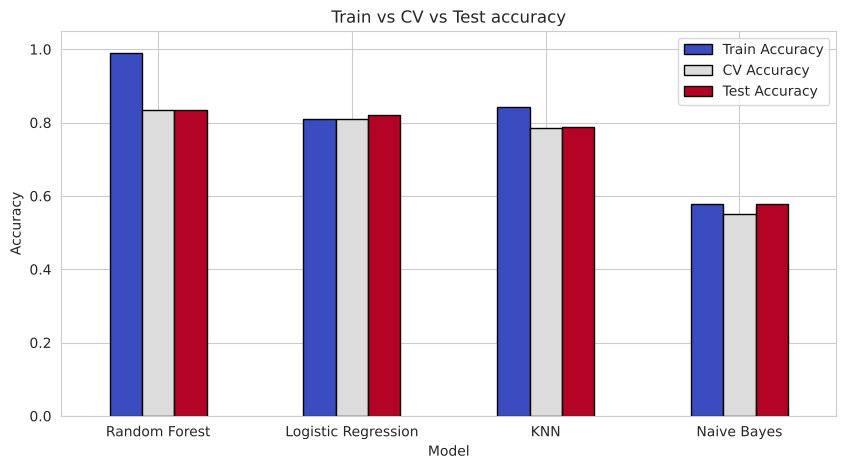

In [38]:
# Train vs Test accuracy (overfitting check)
check_df = results_df.set_index("Model")[["Train Accuracy", "CV Accuracy", "Test Accuracy"]]

check_df.plot(kind="bar", figsize=(10, 5), colormap="coolwarm", edgecolor="black")
plt.title("Train vs CV vs Test accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

**Overfitting kaise pehchane:** agar Train accuracy bahut zyada aur Test accuracy kaafi kam ho, to model ratta maar raha hai (overfitting). Gap jitna chhota, utna achha.

### 8.1 Confusion Matrix
Rows = asli class, Columns = model ki prediction. Diagonal par jitne zyada numbers, utna achha.

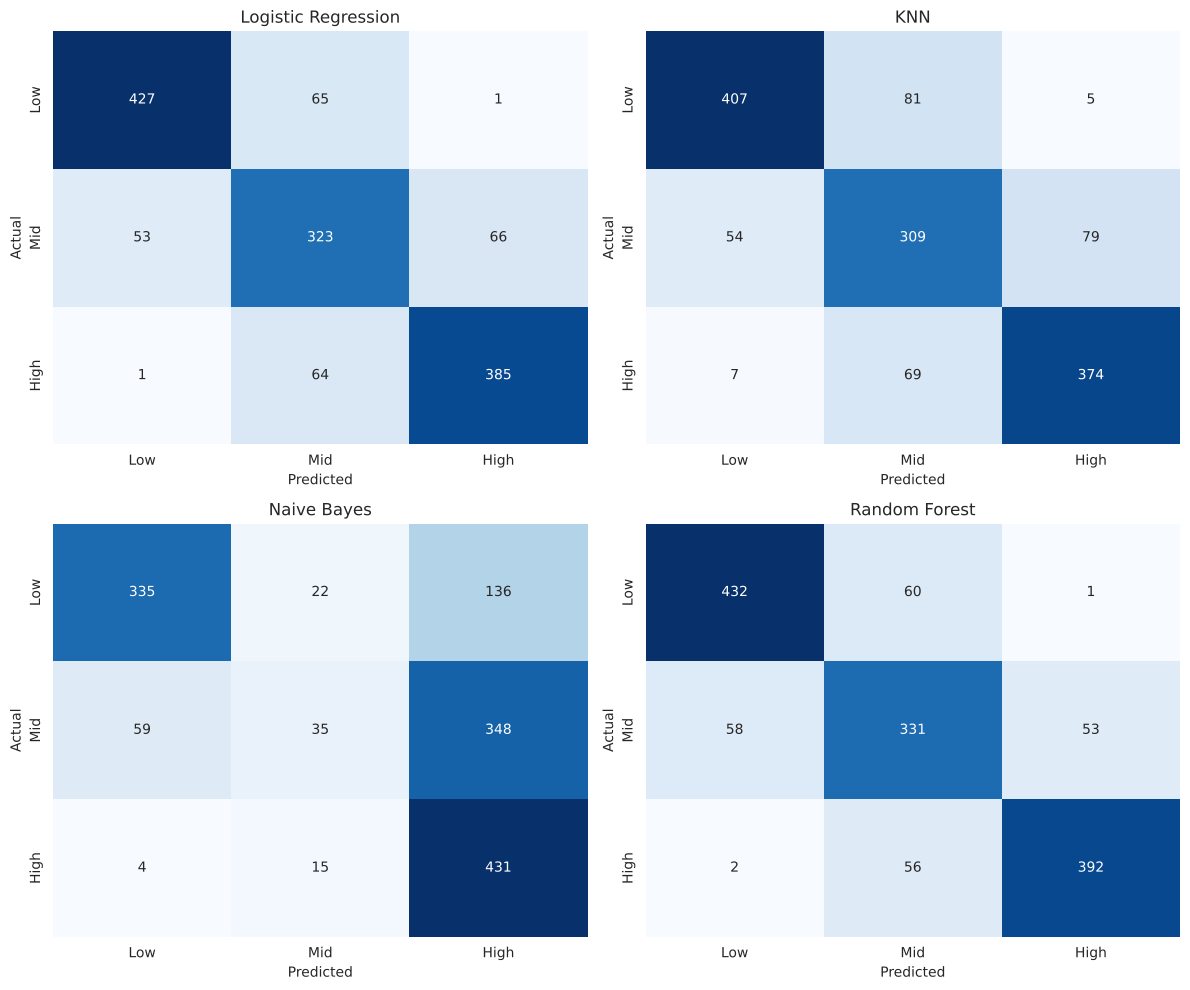

In [39]:
class_names = ["Low", "Mid", "High"]
model_names = ["Logistic Regression", "KNN", "Naive Bayes", "Random Forest"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i in range(4):
    name = model_names[i]
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### 8.2 Best model ki detailed report

In [40]:
best_model_name = results_df.loc[0, "Model"]
print("BEST MODEL:", best_model_name)
print()
print(classification_report(y_test, predictions[best_model_name], target_names=class_names))

BEST MODEL: Random Forest

              precision    recall  f1-score   support

         Low       0.88      0.88      0.88       493
         Mid       0.74      0.75      0.74       442
        High       0.88      0.87      0.88       450

    accuracy                           0.83      1385
   macro avg       0.83      0.83      0.83      1385
weighted avg       0.83      0.83      0.83      1385



### 8.3 Random Forest: kaun se features sabse important hain?

car_age         0.225
torque_nm       0.115
max_power       0.111
km_driven       0.104
km_per_year     0.090
power_per_cc    0.079
mileage         0.068
engine          0.061
owner_num       0.037
seats           0.018
dtype: float64


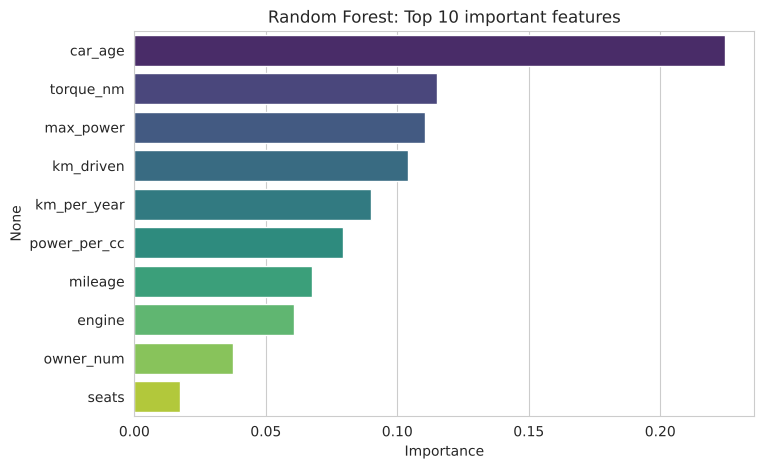

In [41]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns)
top_importance = importance.sort_values(ascending=False).head(10)
print(top_importance.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(x=top_importance.values, y=top_importance.index, palette="viridis")
plt.title("Random Forest: Top 10 important features")
plt.xlabel("Importance")
plt.show()

**Naive Bayes ka score kam kyun aaya?**
Naive Bayes ka **test accuracy 57.8%** aur **F1 0.51** aaya, jo baaki teeno models se bahut kam hai (phir bhi random guess ke 33% se behtar hai). Wajah:
1. **Independence assumption toot-ta hai:** NB maanta hai ki saare features ek doosre se independent hain. Par engine, max_power aur torque_nm aapas me strongly correlated hain, aur car_age aur km_driven bhi.
2. **Gaussian assumption:** GaussianNB har feature ko bell-curve (normal) maanta hai. Yahan km_driven jaise features skewed hain aur 0/1 one-hot columns normal distribution nahi hote.
3. Price in features ke **combination** se decide hota hai (power + age + brand sath me), jabki NB har feature ko alag-alag tolta hai.

Ye ek valid finding hai: **har model har data par achha nahi chalta.**

### ✅ Objective 5 ka jawab

In [42]:
best_row = results_df.loc[0]
print("Best model       :", best_row["Model"])
print("Test accuracy    :", best_row["Test Accuracy"])
print("Macro F1-score   :", best_row["F1-score"])
print()
print("Ranking (F1 ke hisaab se):")
for i in range(len(results_df)):
    print(i + 1, ".", results_df.loc[i, "Model"], "-> F1 =", results_df.loc[i, "F1-score"])

Best model       : Random Forest
Test accuracy    : 0.8339
Macro F1-score   : 0.8323

Ranking (F1 ke hisaab se):
1 . Random Forest -> F1 = 0.8323
2 . Logistic Regression -> F1 = 0.8177
3 . KNN -> F1 = 0.7856
4 . Naive Bayes -> F1 = 0.5066


## 9. Key Findings, Conclusion aur Recommendations

### 📌 Key Findings
1. Dataset me **1,202 duplicate rows** (~15%) aur ~3% missing values thi, aur mileage/torque/engine/max_power text me alag-alag units me the. Cleaning ke baad **6,921 cars** bachi.
2. **Price ke sabse bade drivers:** max_power, torque, engine (positive) aur car_age (negative). Random Forest ke hisaab se sabse important feature **car_age (0.225)** hai, phir torque_nm, max_power aur km_driven.
3. **Depreciation tez hai:** 0-3 saal wali car ka median price 6.55 lakh hai, 10+ saal wali ka 1.4 lakh (~79% kam).
4. **Diesel** aur **Automatic** cars ka price zyada hai, par ye partly isliye ki ye cars premium/nayi hoti hain.
5. **Owner count** badhne par price girta hai (First Owner 5.0 lakh se Fourth & Above 1.7 lakh). **Dealer** cars ka price Individual se zyada hai.
6. **Model comparison (Test accuracy / Macro F1):**

| Model | Test Accuracy | Macro F1 |
|---|---|---|
| Random Forest | 0.834 | 0.832 |
| Logistic Regression | 0.820 | 0.818 |
| KNN (K=7) | 0.787 | 0.786 |
| Naive Bayes | 0.578 | 0.507 |

7. Teeno classes me **Mid** class predict karna sabse mushkil hai (F1 ~0.74), jabki Low aur High ka F1 ~0.88 hai. Ye natural hai kyunki Mid class dono taraf ki boundary ke beech hai.

### 🏁 Conclusion
**Random Forest sabse best model** nikla: test accuracy **83.4%** aur macro F1 **0.832**. Logistic Regression sirf thoda peeche hai (82.0%), jo ek simple aur fast model ke liye achha result hai. KNN 78.7% par raha, aur Naive Bayes 57.8% par sabse kamzor raha kyunki uske independence assumptions is data par fit nahi hote.

Random Forest ka **train accuracy 99%** hai jabki test 83%, yaani thoda overfitting hai. Phir bhi 5-fold CV (83.5%) aur test (83.4%) ek jaise hain, isliye result bharose layak hai. Logistic Regression ka train aur test accuracy lagbhag barabar hai (81% aur 82%), isliye wo zyada stable hai.

Overall, ek used car ka price segment (Low / Mid / High) uski **age, power, torque, km driven aur brand** dekh kar lagbhag 5 me se 4 baar sahi predict kiya ja sakta hai.

### 💡 Recommendations
**Buyers ke liye:**
- Budget kam ho to 4-7 saal purani, First Owner, Petrol/Manual car dekho. Age ke saath price tezi se girta hai, isliye value-for-money wahin milti hai.
- Dealer se lene par price zyada hota hai, par aksar nayi aur better condition ki car milti hai. Individual se sasti car mil sakti hai, par inspection zaroor karwao.

**Sellers ke liye:**
- Jaldi bechne se price kam girta hai. Har 3-4 saal me car ki value kaafi ghat jati hai.
- Kam owners aur kam km wali car ka price zyada milta hai, isliye service record aur ownership history saaf rakho.

**Dealers / platforms ke liye:**
- Random Forest model ko ek **quick price-segment estimator** ki tarah use kiya ja sakta hai (listing ko Low/Mid/High me daalne ke liye).
- Mid segment me model ki galti zyada hai, isliye wahan manual review ya zyada features (city, car condition) jodna chahiye.

**Model ke liye:**
- Random Forest ko `max_depth` ya `min_samples_leaf` se tune karke overfitting kam kiya ja sakta hai.

### ⚠️ Limitations
- Data 2020 tak ke cars ka snapshot hai, aaj ke market rates alag ho sakte hain.
- Price classes quantile se bani hain, isliye class ke edge par (boundary ke paas) wali cars me galti zyada hoti hai.
- Naive Bayes ke assumptions is data par fit nahi hote.
- Missing values median/mode se bhari gayi hain (simple approach).

### 🔭 Future Work
- Price ko seedha predict karne ke liye **regression** models (Linear, Random Forest Regressor) try karna.
- `GridSearchCV` se Random Forest ke parameters tune karna.
- City/region jaisi columns jodna (agar data mile).

In [43]:
# Cleaned dataset save karo (project submission me dataset ke saath ye bhi laga sakte ho)
df.to_csv("cleaned_car_data.csv", index=False)
print("cleaned_car_data.csv save ho gayi. Shape:", df.shape)

cleaned_car_data.csv save ho gayi. Shape: (6921, 23)
